# OpenAI Decisions API in Microsoft Foundry

> https://techcommunity.microsoft.com/blog/azure-ai-foundry-blog/azure-openai-decisions-api-now-generally-available-in-microsoft-foundry/4567265

In [1]:
import base64
import io
import json
import matplotlib.pyplot as plt
import numpy as np
import openai
import os
import pandas as pd
import statistics
import sys
import time

from azure.identity import DefaultAzureCredential, get_bearer_token_provider
from concurrent.futures import ThreadPoolExecutor
from dotenv import load_dotenv
from openai import OpenAI
from PIL import Image, ImageDraw
from typing import Any

In [2]:
sys.version

'3.12.12 | packaged by Anaconda, Inc. | (main, Oct 21 2025, 20:05:38) [MSC v.1929 64 bit (AMD64)]'

In [3]:
load_dotenv("azure.env")

endpoint = os.getenv("endpoint")
scope: str = "https://cognitiveservices.azure.com/.default"

token_provider = get_bearer_token_provider(DefaultAzureCredential(), scope)

DEPLOYMENT: str = "gpt-6-luna"
USE_ENTRA_ID = 1

## Helper

In [4]:
def build_client(use_entra_id: bool = USE_ENTRA_ID) -> OpenAI:
    """Create an OpenAI client pointed at the Azure OpenAI v1 endpoint.

    Args:
        use_entra_id: If True, authenticate with Microsoft Entra ID (bearer token),
            otherwise use the AZURE_OPENAI_API_KEY environment variable.

    Returns:
        A configured OpenAI client.
    """
    if use_entra_id:
        from azure.identity import DefaultAzureCredential, get_bearer_token_provider

        token_provider = get_bearer_token_provider(
            DefaultAzureCredential(), "https://ai.azure.com/.default")
        return OpenAI(base_url=endpoint, api_key=token_provider)
    return OpenAI(base_url=endpoint,
                  api_key=os.environ["AZURE_OPENAI_API_KEY"])


client: OpenAI = build_client()

In [5]:
def to_dict(raw: Any) -> dict[str, Any]:
    """Convert an SDK response (pydantic model or dict) to a plain dict.

    Args:
        raw: The raw object returned by the SDK.

    Returns:
        A JSON-compatible dictionary.
    """
    if isinstance(raw, dict):
        return raw
    if hasattr(raw, "model_dump"):
        return raw.model_dump()
    return json.loads(json.dumps(raw, default=str))


def decide(
    input_: Any,
    questions: list[dict[str, Any]],
    model: str = DEPLOYMENT,
    **extra: Any,
) -> tuple[dict[str, Any], float]:
    """Call POST /openai/v1/decisions and measure latency.

    The generic client.post is used so the notebook works whatever the SDK version.

    Args:
        input_: Shared evidence (string, or list of messages and tool items).
        questions: List of question definitions.
        model: Deployment name.
        **extra: Additional request fields (prompt_cache_key, ...).

    Returns:
        A tuple (response as dict, latency in seconds).
    """
    body: dict[str, Any] = {
        "model": model,
        "input": input_,
        "questions": questions,
        **extra
    }
    start = time.perf_counter()
    raw = client.post("/decisions", body=body, cast_to=object)
    return to_dict(raw), time.perf_counter() - start


def answers_by_name(response: dict[str, Any]) -> dict[str, dict[str, Any]]:
    """Index answers by question name (falls back to position).

    Args:
        response: Decisions API response as dict.

    Returns:
        Mapping question name to answer dict.
    """
    return {
        a.get("name") or f"q{i}": a
        for i, a in enumerate(response["answers"])
    }


def probs_as_dict(answer: dict[str, Any]) -> dict[str, float]:
    """Normalize the per-option probabilities of a choice or score answer.

    Args:
        answer: A choice or score answer.

    Returns:
        Mapping option label (or value) to probability.
    """
    probs = answer.get("probabilities", [])
    if isinstance(probs, dict):
        return {str(k): float(v) for k, v in probs.items()}
    out: dict[str, float] = {}
    for item in probs:
        key = item.get("label", item.get("value"))
        out[str(key)] = float(item["probability"])
    return out


def summarize(answer: dict[str, Any]) -> str:
    """Return a one-line human summary of an answer, refusals included.

    Args:
        answer: A single answer dict.

    Returns:
        A short description string.
    """
    kind = answer["type"]
    if kind == "refusal":
        return f"[refusal] {answer.get('name')}"
    if kind == "predicate":
        return f"[predicate] {answer['name']}: p={answer['probability']:.3f}"
    if kind == "choice":
        return f"[choice] {answer['name']}: {answer['choice']} (confidence={answer['confidence']:.2f})"
    if kind == "score":
        return f"[score] {answer['name']}: {answer['score']:.2f} (confidence={answer['confidence']:.2f})"
    return str(answer)

## Predicate: is a condition true?

Each question gets a unique `name`. The answer is a probability, to be compared with a threshold chosen by the application.

In [6]:
decision = client.decisions.create(
    model=DEPLOYMENT,
    input="The box arrived crushed and the screen is cracked.",
    questions=[
        {"type": "predicate", "name": "damaged",
         "instructions": "Does the customer report a damaged item?"}
    ],
)

print(decision.answers[0].probability)

1.0


In [7]:
print(decision.model_dump_json(indent=4))

{
    "answers": [
        {
            "name": "damaged",
            "probability": 1.0,
            "type": "predicate"
        }
    ],
    "model": "gpt-6-luna",
    "usage": {
        "input_tokens": 166,
        "input_tokens_details": {
            "cache_write_tokens": 0,
            "cached_tokens": 0
        },
        "output_tokens": 0,
        "output_tokens_details": {
            "reasoning_tokens": 0
        },
        "total_tokens": 166
    }
}


In [8]:
print(f"Model: {decision.model}")
print("Answers:")
for answer in decision.answers:
    print(f"  - {answer.name}: {answer.probability:.1%} ({answer.type})")

usage = decision.usage
print(
    f"Tokens: {usage.input_tokens} in, "
    f"{usage.output_tokens} out, "
    f"{usage.total_tokens} total"
)

Model: gpt-6-luna
Answers:
  - damaged: 100.0% (predicate)
Tokens: 166 in, 0 out, 166 total


In [9]:
messages: list[str] = [
    "I was charged twice for my order. Please return the extra charge.",
    "Where is my parcel? It was supposed to arrive yesterday.",
    "Thanks, everything works great now.",
    "I want my money back, this product is broken.",
]

rows: list[dict[str, Any]] = []

for text in messages:
    resp, latency = decide(
        text,
        [{
            "type": "predicate",
            "name": "refund_requested",
            "instructions": "Does the customer ask for a refund?",
        }],
    )
    ans = answers_by_name(resp)["refund_requested"]
    rows.append({
        "message": text,
        "probability": ans.get("probability"),
        "type": ans["type"],
        "latency_s": round(latency, 3),
    })

In [10]:
rows

[{'message': 'I was charged twice for my order. Please return the extra charge.',
  'probability': 1.0,
  'type': 'predicate',
  'latency_s': 0.711},
 {'message': 'Where is my parcel? It was supposed to arrive yesterday.',
  'probability': 0.0,
  'type': 'predicate',
  'latency_s': 0.512},
 {'message': 'Thanks, everything works great now.',
  'probability': 0.0,
  'type': 'predicate',
  'latency_s': 0.61},
 {'message': 'I want my money back, this product is broken.',
  'probability': 1.0,
  'type': 'predicate',
  'latency_s': 0.937}]

In [11]:
pd.DataFrame(rows)

,message,probability,type,latency_s
0,I was charged twice for my order. Please retur...,1.0,predicate,0.711
1,Where is my parcel? It was supposed to arrive ...,0.0,predicate,0.512
2,"Thanks, everything works great now.",0.0,predicate,0.610
3,"I want my money back, this product is broken.",1.0,predicate,0.937


In [12]:
# Look at the raw response once (shape, usage)
resp, _ = decide(messages[0],
                 [{
                     "type": "predicate",
                     "name": "refund_requested",
                     "instructions": "Does the customer ask for a refund?"
                 }])

print(json.dumps(resp, indent=4))

{
    "model": "gpt-6-luna",
    "answers": [
        {
            "type": "predicate",
            "name": "refund_requested",
            "probability": 1.0
        }
    ],
    "usage": {
        "input_tokens": 170,
        "input_tokens_details": {
            "cached_tokens": 0,
            "cache_write_tokens": 0
        },
        "output_tokens": 0,
        "output_tokens_details": {
            "reasoning_tokens": 0
        },
        "total_tokens": 170
    }
}


## Choice: select one option from a fixed set

Include a fallback option (`other`). The answer contains `choice`, the per-option probabilities and `confidence`.

In [13]:
DEPARTMENTS: list[dict[str, str]] = [
    {
        "value": "billing",
        "description": "Payments, invoices, and refunds."
    },
    {
        "value": "technical",
        "description": "Problems using the product."
    },
    {
        "value": "shipping",
        "description": "Delivery and tracking."
    },
    {
        "value": "other",
        "description": "Requests outside these categories."
    },
]


def route(text: str) -> dict[str, Any]:
    """Route a customer message to a department with a choice question.

    Args:
        text: The customer message.

    Returns:
        The choice answer dict.
    """
    resp, _ = decide(text, [{
        "type": "choice",
        "name": "department",
        "instructions": "Which department should handle this complaint?",
        "choices": DEPARTMENTS,
    }])
    return answers_by_name(resp)["department"]

In [14]:
ans = route("I was charged twice for my order.")
print(summarize(ans))

pd.Series(probs_as_dict(ans),
          name="probability").sort_values(ascending=False).to_frame()

[choice] department: billing (confidence=1.00)


,probability
billing,1.0
technical,0.0
shipping,0.0
other,0.0


## Score: rate against an ordered rubric (2 to 10 levels)

Indices start at 0. The `score` is the probability-weighted average of the indices, so it can fall between two levels.

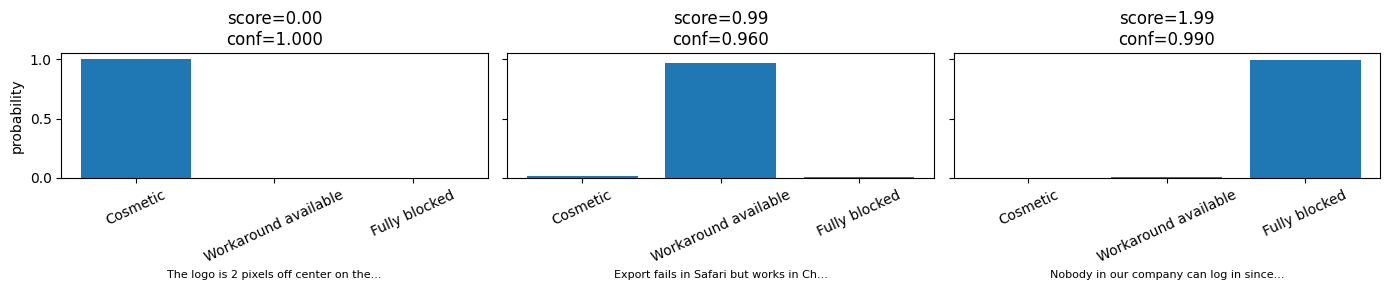

In [15]:
SEVERITY_LEVELS: list[dict[str, str]] = [
    {
        "label": "Cosmetic",
        "description": "Appearance only; no lost functionality."
    },
    {
        "label": "Workaround available",
        "description": "A task fails, but another way works."
    },
    {
        "label": "Fully blocked",
        "description": "A task fails with no workaround."
    },
]

issues: list[str] = [
    "The logo is 2 pixels off center on the settings page.",
    "Export fails in Safari but works in Chrome.",
    "Nobody in our company can log in since this morning.",
]

fig, axes = plt.subplots(1, len(issues), figsize=(14, 3), sharey=True)

for ax, issue in zip(axes, issues):
    resp, _ = decide(issue, [{
        "type": "score",
        "name": "severity",
        "instructions": "How severe is this issue?",
        "levels": SEVERITY_LEVELS,
    }])
    ans = answers_by_name(resp)["severity"]
    probs = probs_as_dict(ans)
    ax.bar(list(probs.keys()), list(probs.values()))
    ax.set_title(f"score={ans['score']:.2f}\nconf={ans['confidence']:.3f}",
                 fontsize=12)
    ax.set_xlabel(issue[:38] + "...", fontsize=8)
    ax.tick_params(axis="x", rotation=25)

axes[0].set_ylabel("probability")
plt.tight_layout()
plt.show()

## Native call through the OpenAI SDK (`client.decisions.create`)

Available if the installed SDK version exposes the `decisions` resource. The rest of the notebook uses `client.post` to stay independent of the SDK version.

In [16]:
if hasattr(client, "decisions"):
    decision = client.decisions.create(
        model=DEPLOYMENT,
        input=
        "I was charged twice for my order. Please return the extra charge.",
        questions=[{
            "type": "predicate",
            "name": "refund_requested",
            "instructions": "Does the customer ask for a refund?",
        }],
    )

    answer = decision.answers[0]

    if answer.type == "predicate":
        print(f"Refund requested probability = {answer.probability}")
    elif answer.type == "refusal":
        print(f"Refused: {answer.name}")
else:
    print(
        "This SDK version has no client.decisions yet: run  %pip install --upgrade openai"
    )

Refund requested probability = 1.0


In [17]:
answer

AnswerAnswerResourcePredicate(name='refund_requested', probability=1.0, type='predicate')

## Several questions in a single request

Up to 400 questions of mixed types on the same input. We compare one grouped request with sequential requests.

In [18]:
TICKET: str = (
    "Hello, my invoice shows two charges of 49 EUR and since the last update the app "
    "crashes on startup, I cannot even open it. This is urgent, I have a client demo today."
)

QUESTIONS: list[dict[str, Any]] = [
    {"type": "predicate", "name": "refund_requested", "instructions": "Does the customer ask for a refund or a charge correction?"},
    {"type": "predicate", "name": "mentions_crash", "instructions": "Does the customer report an application crash?"},
    {"type": "choice", "name": "department", "instructions": "Which department should handle this ticket first?", "choices": DEPARTMENTS},
    {"type": "score", "name": "urgency", "instructions": "How urgent is this ticket?",
     "levels": [
         {"label": "Routine", "description": "No time pressure."},
         {"label": "Time-sensitive", "description": "Deadline mentioned but a workaround exists."},
         {"label": "Critical", "description": "Customer is blocked now."},
     ]},
]

batched, t_batched = decide(TICKET, QUESTIONS)

for a in batched["answers"]:
    print(summarize(a))

t_seq = 0.0
print()

for q in QUESTIONS:
    _, dt = decide(TICKET, [q])
    t_seq += dt

    print(f"One request with {len(QUESTIONS)} questions: {t_batched:.2f}s | {len(QUESTIONS)} sequential requests: {t_seq:.2f}s")

print("\nUsage:", batched.get("usage"))

[predicate] refund_requested: p=0.060
[predicate] mentions_crash: p=1.000
[choice] department: billing (confidence=0.91)
[score] urgency: 2.00 (confidence=1.00)

One request with 4 questions: 0.96s | 4 sequential requests: 0.53s
One request with 4 questions: 0.96s | 4 sequential requests: 1.05s
One request with 4 questions: 0.96s | 4 sequential requests: 1.62s
One request with 4 questions: 0.96s | 4 sequential requests: 2.62s

Usage: {'input_tokens': 609, 'input_tokens_details': {'cached_tokens': 0, 'cache_write_tokens': 0}, 'output_tokens': 0, 'output_tokens_details': {'reasoning_tokens': 0}, 'total_tokens': 609}


## Image input

PNG, JPG, WebP, GIF. `image_url` accepts a base64 data URL or a public HTTPS URL (never a local file name). Here we generate two synthetic images so the notebook does not depend on any file.

In [19]:
def image_to_data_url(image: Image.Image, fmt: str = "PNG") -> str:
    """Encode a PIL image as a base64 data URL.

    Args:
        image: The PIL image.
        fmt: Image format (PNG, JPEG, WEBP, GIF).

    Returns:
        A data URL string usable in an input_image part.
    """
    buffer = io.BytesIO()
    image.save(buffer, format=fmt)
    encoded = base64.b64encode(buffer.getvalue()).decode("ascii")
    return f"data:image/{fmt.lower()};base64,{encoded}"


def file_to_data_url(path: str, mime: str = "image/png") -> str:
    """Encode an image file as a base64 data URL.

    Args:
        path: Path to the image file.
        mime: MIME type of the file.

    Returns:
        A data URL string.
    """
    with open(path, "rb") as handle:
        return f"data:{mime};base64,{base64.b64encode(handle.read()).decode('ascii')}"

In [20]:
image1 = "image1.png"
image2 = "image2.png"

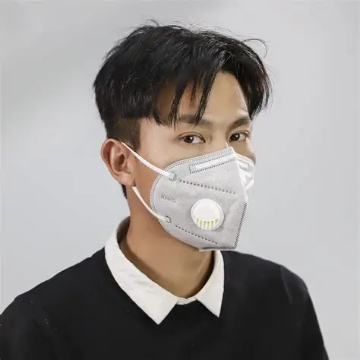

In [21]:
img1 = Image.open(image1)
img1

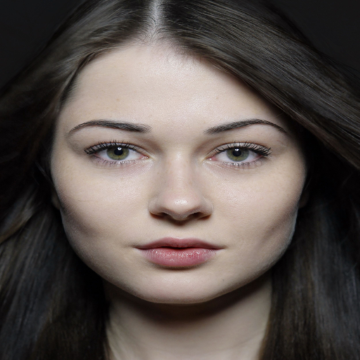

In [22]:
img2 = Image.open(image2)
img2

In [23]:
MASK_Q: dict[str, Any] = {
    "type": "predicate",
    "name": "mask",
    "instructions": "Does this person is wearing a mask?",
}

for label, im in (("image1", img1), ("image2", img2)):
    resp, dt = decide(
        [{
            "role":
            "user",
            "content": [
                {
                    "type": "input_text",
                    "text": "Inspect the person in this photo."
                },
                {
                    "type": "input_image",
                    "image_url": image_to_data_url(im)
                },
            ]
        }],
        [MASK_Q],
    )
    
    print(f"{label:8s}: {summarize(resp['answers'][0])} ({dt:.2f}s)")

image1  : [predicate] mask: p=1.000 (1.11s)
image2  : [predicate] mask: p=0.000 (0.95s)


In [24]:
MOUTH_Q: dict[str, Any] = {
    "type": "predicate",
    "name": "mouth_is_visible",
    "instructions": "Can we see the mouth of the person?",
}

for label, im in (("image1", img1), ("image2", img2)):
    resp, dt = decide(
        [{
            "role":
            "user",
            "content": [
                {
                    "type": "input_text",
                    "text": "Mouth visible"
                },
                {
                    "type": "input_image",
                    "image_url": image_to_data_url(im)
                },
            ]
        }],
        [MOUTH_Q],
    )
    
    print(f"{label:8s}: {summarize(resp['answers'][0])} ({dt:.2f}s)")

image1  : [predicate] mouth_is_visible: p=0.000 (1.10s)
image2  : [predicate] mouth_is_visible: p=1.000 (1.41s)


## JSON input (`input_json`)

Structured data is passed as is. Keys such as `role` or `image_url` inside `data` remain plain data. `input_json` is only accepted for the `user` role.

In [25]:
resp, dt = decide(
    [{"role": "user", "content": [
        {"type": "input_text", "text": "Evaluate the ticket using the order evidence."},
        {"type": "input_json", "data": {
            "ticket": {"body": "Please refund the duplicate charge."},
            "order": {"charges": [49, 49]},
        }},
    ]}],
    [{"type": "predicate", "name": "duplicate_charge",
      "instructions": "Does the ticket describe a duplicate charge supported by the order?"}],
)

print(summarize(resp["answers"][0]), f"({dt:.2f}s)")

[predicate] duplicate_charge: p=0.970 (0.58s)


In [26]:
# Counter-example: the order shows a single charge
resp, dt = decide(
    [{"role": "user", "content": [
        {"type": "input_text", "text": "Evaluate the ticket using the order evidence."},
        {"type": "input_json", "data": {
            "ticket": {"body": "Please refund the duplicate charge."},
            "order": {"charges": [49]},
        }},
    ]}],
    [{"type": "predicate", "name": "duplicate_charge",
      "instructions": "Does the ticket describe a duplicate charge supported by the order?"}],
)

print(summarize(resp["answers"][0]), f"({dt:.2f}s)")

[predicate] duplicate_charge: p=0.080 (0.56s)


## Evaluate a conversation with tool calls

`input` accepts ordered messages, function calls and their outputs (linked by `call_id`). Decisions only returns typed answers, your application runs the actions.

The item format follows the Responses API. On a 400 error, compare with OpenAI's `create decision` reference.

In [27]:
conversation: list[dict[str, Any]] = [
    {"role": "developer", "content": "You are a support assistant for an online store."},
    {"role": "user", "content": "Where is my order 8841? I paid two weeks ago."},
    {"type": "function_call", "call_id": "call_1", "name": "get_order_status",
     "arguments": json.dumps({"order_id": "8841"})},
    {"type": "function_call_output", "call_id": "call_1",
     "output": json.dumps({"status": "lost_in_transit", "paid": True, "days_since_payment": 14})},
    {"role": "assistant", "content": [{"type": "output_text", "text": "I am sorry, your parcel seems lost."}]},
    {"role": "user", "content": "Then I want a refund right now."},
]

try:
    resp, dt = decide(conversation, [
        {"type": "predicate", "name": "refund_justified",
         "instructions": "Given the tool output, is a refund justified?"},
        {"type": "choice", "name": "next_action", "instructions": "What should the agent do next?",
         "choices": [
             {"value": "issue_refund", "description": "Refund the customer."},
             {"value": "reship", "description": "Send a replacement."},
             {"value": "escalate", "description": "Hand over to a human."},
         ]},
    ])
    for a in resp["answers"]:
        print(summarize(a))

except openai.APIStatusError as exc:
    print(f"HTTP {exc.status_code}: {exc.message}")

[predicate] refund_justified: p=1.000
[choice] next_action: escalate (confidence=0.61)


## Refusals and robustness

A question can return `type: "refusal"` while the others still get their answer. Always check `type` before reading the result. A refusal is not a low probability: route it to a human review.

In [28]:
def safe_probability(answer: dict[str, Any], threshold: float = 0.5) -> bool | None:
    """Turn a predicate answer into a boolean, or None for a refusal.

    Args:
        answer: A predicate or refusal answer.
        threshold: Decision threshold applied on the probability.

    Returns:
        True or False, or None when the model refused (send to human review).
    """
    if answer["type"] == "refusal":
        return None
    return float(answer["probability"]) >= threshold

In [29]:
resp, _ = decide(TICKET, QUESTIONS)

for a in resp["answers"]:
    if a["type"] == "predicate":
        print(a["name"], "->", safe_probability(a))

refund_requested -> False
mentions_crash -> True


## Prompt caching on a shared input

A prefix of at least 1024 tokens in `input` is reusable across requests (only the content of `questions` changes). Read `usage.input_tokens_details.cached_tokens`. `prompt_cache_key` lets you partition the cache.

In [30]:
POLICY: str = "\n".join(
    f"Rule {i}: Refunds for category C{i % 7} are allowed within {10 + i % 20} days when the item is "
    f"unused, the invoice is attached, and the customer account is in good standing."
    for i in range(1, 161)
)

cache_questions: list[list[dict[str, Any]]] = [
    [{"type": "predicate", "name": "mentions_invoice", "instructions": "Does the policy mention an invoice?"}],
    [{"type": "predicate", "name": "mentions_account", "instructions": "Does the policy mention the customer account?"}],
    [{"type": "predicate", "name": "mentions_shipping", "instructions": "Does the policy mention shipping costs?"}],
]

for i, qs in enumerate(cache_questions, start=1):
    resp, dt = decide(POLICY, qs, prompt_cache_key="policy-demo")
    usage = resp.get("usage", {})
    details = usage.get("input_tokens_details") or {}
    print(f"call {i}: {dt:.3f}s | input_tokens={usage.get('input_tokens')} "
          f"cached={details.get('cached_tokens')} cache_write={details.get('cache_write_tokens')}")

call 1: 0.851s | input_tokens=5915 cached=5763 cache_write=0
call 2: 0.727s | input_tokens=5916 cached=5763 cache_write=0
call 3: 0.577s | input_tokens=5915 cached=5763 cache_write=0


## Validation and errors

Check how the API behaves on invalid requests (a rubric with a single level, no question, unsupported local image path).

In [31]:
def expect_error(label: str, input_: Any, questions: list[dict[str,
                                                               Any]]) -> None:
    """Send an invalid request and print the HTTP error returned.

    Args:
        label: Short description of the test case.
        input_: Input payload.
        questions: Questions payload.
    """
    try:
        decide(input_, questions)
        print(f"{label}: accepted (no error)")
    except openai.APIStatusError as exc:
        print(f"{label}: HTTP {exc.status_code} | {str(exc.message)[:160]}")


In [32]:
expect_error("score with 1 level", "text", [{
    "type": "score",
    "name": "s",
    "instructions": "x",
    "levels": [{
        "label": "only"
    }]
}])
expect_error("no question", "text", [])
expect_error("local file name as image",
             [{
                 "role": "user",
                 "content": [{
                     "type": "input_image",
                     "image_url": "product.png"
                 }]
             }], [{
                 "type": "predicate",
                 "name": "p",
                 "instructions": "Is there a product?"
             }])

score with 1 level: HTTP 400 | Error code: 400 - {'error': {'message': "Invalid 'questions[0].levels': array too short. Expected an array with minimum length 2, but got an array with length 1
no question: HTTP 400 | Error code: 400 - {'error': {'message': "Invalid 'questions': empty array. Expected an array with minimum length 1, but got an empty array instead.", 'type': 'i
local file name as image: HTTP 400 | Error code: 400 - {'error': {'message': "Invalid 'input[0].content[0].image_url': string does not match pattern. Expected a string that matches the pattern '^(d


## Key takeaways

| Topic | Finding to validate with your own measurements |
| --- | --- |
| Model | `gpt-6-luna` only, the `model` field is the deployment name |
| Types | predicate, choice, score (2 to 10 levels) |
| Inputs | text, images (PNG, JPG, WebP, GIF), JSON, conversation with tools |
| Volume | up to 400 questions per request, 128 images and 32 MB per request |
| Cache | shared prefix of at least 1024 tokens, `prompt_cache_key` to partition |
| Thresholds | to calibrate on labeled examples (section 11) |
| Refusals | handle `refusal` separately, never as a low probability |
| Regions | progressive rollout, East US 2 excluded |

Sources: [Foundry announcement](https://techcommunity.microsoft.com/blog/azure-ai-foundry-blog/azure-openai-decisions-api-now-generally-available-in-microsoft-foundry/4567265), [Microsoft Learn](https://learn.microsoft.com/azure/foundry/openai/how-to/decisions), [OpenAI guide](https://developers.openai.com/api/docs/guides/decisions).